In [1]:
from visualize import Embedding

embedding_baseline = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_no_dispersion/',
        features_path='train.features.npy',
        targets_path='410.train.targets.npy',
        yaml_path="410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096_metadata.yaml",
        faiss_path='410.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc4096'
    )
embedding_dispersion = Embedding(
        base_path='/ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/',
        features_path='582.train.features.npy',
        targets_path='582.train.targets.npy',
        yaml_path="582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml",
        faiss_path='582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096'
    )
embedding_baseline.load_raw()
embedding_dispersion.load_raw()

embedding_baseline.load_faiss()
embedding_dispersion.load_faiss()

/home/stroshi/miniconda3/envs/evgeniia/lib/python3.8/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, nclusters=4096, nprobe=32, ntotal=21507934)
Namespace(code_size=64, corse_index='FlatL2', datastore='IVFPQ', dim=512, features_model='/ivi/ilps/personal/etokarc/models/translation/00582_ro_en_transformer_dispersion_ft/checkpoint_best.pt', nclusters=2048, nprobe=32, ntotal=21507934)


In [2]:
!ls /ivi/ilps/projects/cnmt/knn-mt-dispersion/datastores/model_512_dispersion/

582.roen.X.npy
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_512_4096
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048
582.roen.faiss_L2_IVFPQindex_cs64_nprobe32_d512_nc2048_meta.yaml
582.roen.kmeans
582.train.features.npy
582.train.targets.npy


In [3]:
print(embedding_baseline.knn_index.invlists.imbalance_factor())
print(embedding_dispersion.knn_index.invlists.imbalance_factor())

68.52594283181449
18.123367874076685


In [4]:
# size of a inverted list
for i in range(1024):
    print(embedding_baseline.knn_index.invlists.list_size(i), end=' ')

3954 1236 2750 9626 2020 337 74 6170 1125 2732 609 6393 1343 2452 567 6302 155 222 3114 25182 913 2310 7262 3595 521 4604 1643 264 2212 2 13378 865 939 2 3113 1168 3746 9494 2311 11637 5770 2530 11 10 3125 2878 6255 546 1596 5160 410 1038 2917 863 3139 11639 3254 3472 1840 3183 1840 1768 3615 440 5195 387 3471 48 7400 2648 3507 1627 1206 6700 1563 3134 17 5422 3591 573 1077 6076 3430 3236 1120 1122 4954 2472 5948 4436 539 927 216641 7838 1094 14 4428 2856 12815 9085 678 2219 3184 161 2630 1897 5369 1466 2952 36 3619 1901 13657 34 2417 2138 428 314 1795 2663 220 10931 800 862 3714 34 3313 295 68 1826 6505 451 8393 6740 2931 2928 68 3195 6862 8414 3554 881 4137 142996 1187 1751 3736 4212 9452 3262 2168 1927 7260 2368 72 5345 3484 55 677 28 2431 1684 7570 101 684 301 3152 7420 6852 2676 3264 1891 4683 1066 932 4967 2867 1024 688 1190 3876 5 543 1908 3413 2228 2289 734 1692 3618 1534 503 1331 2109 6318 1774 1460 1502 4398 3273 251 7569 48 1887 465 20307 2017 842 455 3650 1693 1396 2787 854

In [5]:
dir(embedding_baseline.knn_index.invlists)

['INVALID_CODE_SIZE',
 'SUBSET_TYPE_ELEMENT_RANGE',
 'SUBSET_TYPE_ID_MOD',
 'SUBSET_TYPE_ID_RANGE',
 'SUBSET_TYPE_INVLIST',
 'SUBSET_TYPE_INVLIST_FRACTION',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__swig_destroy__',
 '__weakref__',
 'add_entries',
 'add_entry',
 'code_size',
 'compute_ntotal',
 'copy_subset_to',
 'get_codes',
 'get_ids',
 'get_iterator',
 'get_single_code',
 'get_single_id',
 'imbalance_factor',
 'is_empty',
 'list_size',
 'merge_from',
 'nlist',
 'prefetch_lists',
 'print_stats',
 'release_codes',
 'release_ids',
 'reset',
 'resize',
 'this',
 'thisown',
 'update_entries',
 'update_entry',
 'use_iterator']

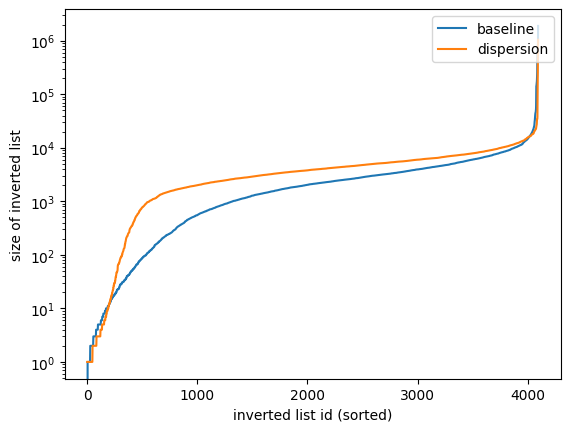

In [6]:
def get_imbalance_histogram(knn_index):
    sizes = []
    # print(knn_index.invlists.code_size)
    # print(knn_index.invlists.nlist)
    for i in range(knn_index.invlists.nlist):
        sizes.append(knn_index.invlists.list_size(i))
    return sizes

sizes_baseline = get_imbalance_histogram(embedding_baseline.knn_index)
sizes_dispersion = get_imbalance_histogram(embedding_dispersion.knn_index)


def make_sizes_plot(sizes_baseline, sizes_dispersion):
    import matplotlib.pyplot as plt
    import numpy as np
    # sortщ
    sizes_baseline = np.sort(sizes_baseline)
    sizes_dispersion = np.sort(sizes_dispersion)

    fig, ax = plt.subplots()
    plt.plot(sizes_baseline, label='baseline')
    plt.plot(sizes_dispersion, label='dispersion')
    ax.legend(loc='upper right')
    ax.set_ylabel('size of inverted list')
    ax.set_xlabel('inverted list id (sorted)')
    # log scale
    ax.set_yscale('log')
    plt.show()

make_sizes_plot(sizes_baseline, sizes_dispersion)



In [7]:
from load_dict import load_en

vocab, idx2word, frequences = load_en()


In [17]:

# make a plot
from collections import defaultdict
import matplotlib.pyplot as plt
import numpy as np




def get_cluster_id_to_values(embedding):

    # save values and corresponding cluster_id(feature)
    cluster_id_to_values = {}   

    for i in range(100000):
        q = embedding.emb(i).astype("float32") # vector to search
        v = embedding.target(i).astype("int32") # vector to search
        q = np.expand_dims(q, axis=0)
        # print(v)
        D, I = embedding.knn_index.quantizer.search(q, k=1)
        # print(D)
        # print(I)

        index = I[0][0]
        if index not in cluster_id_to_values:
            cluster_id_to_values[index] = []
        cluster_id_to_values[index].append(v)

        # sort v_cluster_pairs by cluster id
        cluster_id_to_values = dict(sorted(cluster_id_to_values.items()))
    return cluster_id_to_values


cluster_id_to_values_baseline = get_cluster_id_to_values(embedding_baseline)
cluster_id_to_values_dispersion = get_cluster_id_to_values(embedding_dispersion)

In [18]:
# plot sizes of clusters
def plot_cluster_sizes(cluster_id_to_values):
    fig, axes = plt.subplots(1, 3, figsize=(10, 5))

    sizes = []
    average_frequency = []
    for k, v in cluster_id_to_values.items():
        sizes.append(len(v))
        average_frequency.append(np.mean([frequences[i] for i in v]))
    
    sizes = np.array(sizes)
    average_frequency = np.array(average_frequency)
    idx = np.argsort(average_frequency)
    # sort
    sizes = sizes[idx]
    average_frequency = average_frequency[idx]

    axes[0].plot(sizes, label='size of cluster')
    axes[0].set_xlabel('cluster id')
    axes[0].set_ylabel('size of cluster')
    axes[0].set_title('Cluster sizes for part of values')
    axes[0].legend()
    axes[1].plot(average_frequency, label='average frequency')
    axes[1].set_xlabel('cluster id')
    axes[1].set_ylabel('average frequency')
    axes[1].set_title('Average frequency for part of values')
    axes[1].legend()

    # make scatter plot as well
    axes[2].scatter(sizes, average_frequency)
    axes[2].set_xlabel('size of cluster')
    axes[2].set_ylabel('average frequency')
    axes[2].set_title('Cluster sizes vs average frequency')
    axes[2].legend()
    axes[2].set_xscale('log')
    axes[2].set_yscale('log')
    axes[2].set_aspect('equal', adjustable='box')

    plt.tight_layout()
    plt.show()




No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


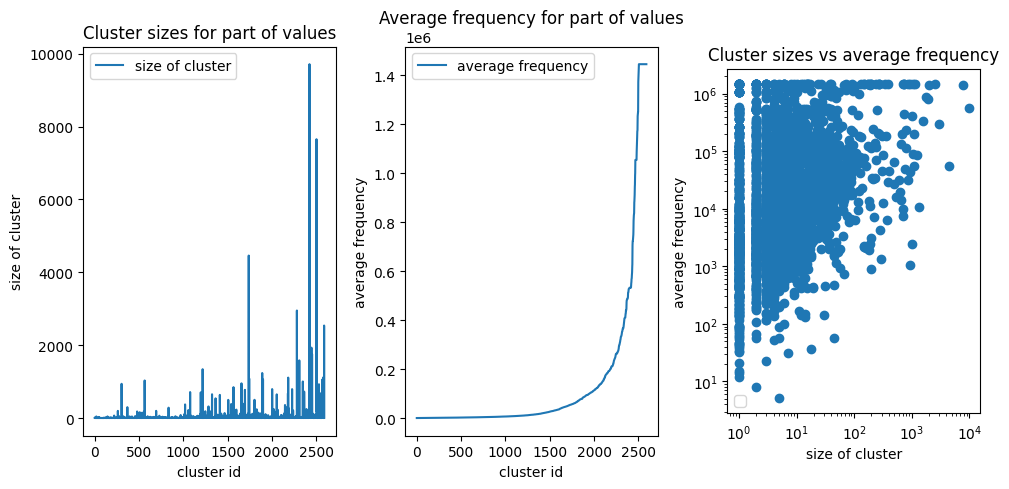

In [19]:
plot_cluster_sizes(cluster_id_to_values_baseline)

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


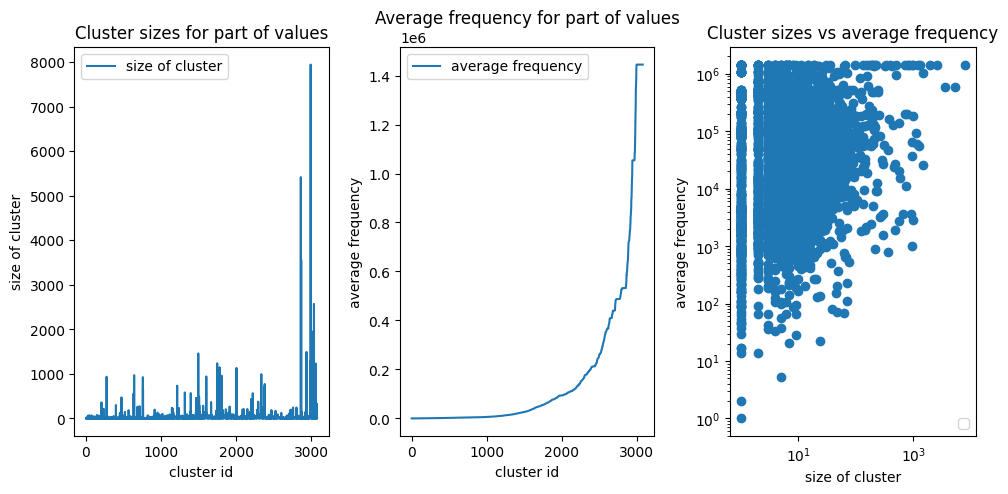

In [20]:
plot_cluster_sizes(cluster_id_to_values_dispersion)

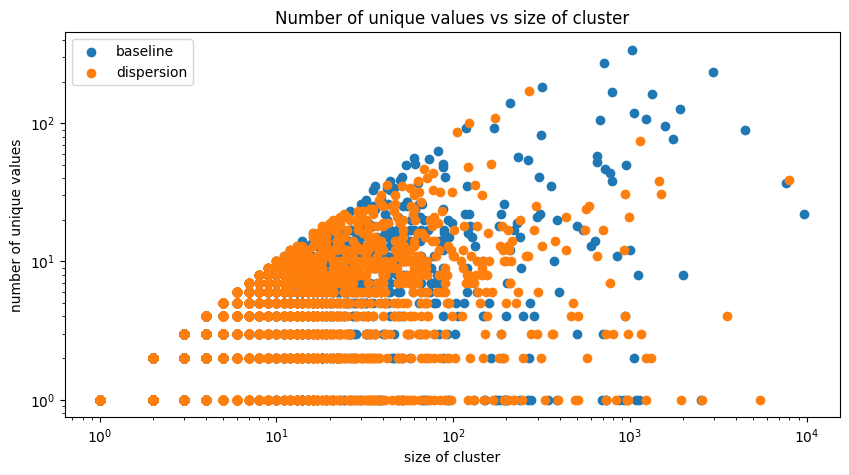

In [39]:
# for each cluster, we plot the number of unique values vs size
def plot_size_vs_unique_values(cluster_id_to_values, label=''):

    sizes = []
    unique_values = []
    for k, v in cluster_id_to_values.items():
        sizes.append(len(v))
        unique_values.append(len(set(v)))
    
    sizes = np.array(sizes)
    unique_values = np.array(unique_values)
    idx = np.argsort(sizes)
    # sort
    sizes = sizes[idx]
    unique_values = unique_values[idx]

    #$ plot a single plot
    plt.scatter(sizes, unique_values, label=label)
    
plt.figure(figsize=(10, 5))
plot_size_vs_unique_values(cluster_id_to_values_baseline, label='baseline')
plot_size_vs_unique_values(cluster_id_to_values_dispersion, label='dispersion')

plt.xlabel('size of cluster')
plt.ylabel('number of unique values')
plt.title('Number of unique values vs size of cluster')

plt.xscale('log')
plt.yscale('log')
plt.legend()
plt.show()

In [26]:
import numpy as np
from heapq import nlargest, nsmallest

def print_top_k_clusters(cluster_id_to_values, idx2word, k=5, unique_tokens=False, which="largest"):
    """
    Print the k largest and k smallest clusters (by membership size).

    Parameters
    ----------
    cluster_id_to_values : dict[int, list[int]]
        Mapping from cluster ID to the list/array of token‑indices in that cluster.
    idx2word : dict[int, str]
        Mapping from token index back to the original word.
    k : int, optional
        Number of clusters to show for each extreme (default 5).
    """
    # ---------- pick cluster IDs ----------
    largest_ids  = nlargest(k, cluster_id_to_values,  key=lambda cid: len(cluster_id_to_values[cid]))
    smallest_ids = nsmallest(k, cluster_id_to_values, key=lambda cid: len(cluster_id_to_values[cid]))

    # ---------- helper for pretty printing ----------
    def _report(ids, kind):
        print(f"\nTop {k} {kind} clusters:")
        for rank, cid in enumerate(ids, start=1):
            values = cluster_id_to_values[cid]
            unique_vals = np.unique(values)
            decoded_vals = [idx2word[i] for i in values]
            average_token_frequency = np.mean([frequences[i] for i in values])

            print(f"\n  #{rank} ({kind[:-1]} cluster id): {cid}  | size = {len(values)}")
            # print("    unique values :", unique_vals)
            if unique_tokens:
                # print unique tokens with counts
                unique_vals, counts = np.unique(values, return_counts=True)
                # sort by counts
                sorted_indices = np.argsort(counts)[::-1]
                unique_vals = unique_vals[sorted_indices]
                counts = counts[sorted_indices]
                detokenized_vals = [idx2word[i] for i in unique_vals]
                print("    unique tokens with counts:", list(zip(detokenized_vals, counts)))
            else:
                print("    all tokens    :", decoded_vals)
            print("    average token frequency:", average_token_frequency)
            

    if which == "largest":
        _report(largest_ids,  which)
    elif which == "smallest":
        _report(smallest_ids, which)
    else:
        raise ValueError(f"Unknown value for 'which': {which}. Must be 'largest' or 'smallest'.")


In [31]:
# ----- usage -----
print_top_k_clusters(cluster_id_to_values_baseline, idx2word, k=8, unique_tokens=True)
# 


Top 8 largest clusters:

  #1 (larges cluster id): 4089  | size = 9711
    unique tokens with counts: [('.', 8667), ('s', 335), (',', 296), ('apos', 156), (';', 136), ('@', 47), ('es', 45), ('▁Union', 7), ('d', 5), ('ly', 3), ('▁European', 2), ('ing', 2), ('▁(', 1), ('rings', 1), ('e', 1), ('▁EU', 1), ('u', 1), ('de', 1), ('Es', 1), ('ward', 1), ('slav', 1), ('zahlen', 1)]
    average token frequency: 569129.7703635053

  #2 (larges cluster id): 4092  | size = 7652
    unique tokens with counts: [('▁', 7494), ('▁and', 31), ('▁of', 27), ('s', 24), ('▁very', 11), ('▁!', 9), ('▁(', 7), ('▁to', 5), ('</s>', 4), ('▁...', 4), ('▁indeed', 3), ('▁in', 3), ('▁that', 2), ('ly', 2), ('▁for', 2), ('▁it', 2), ('▁we', 2), ('▁open', 1), ('▁this', 1), ('▁ones', 1), ('▁everyone', 1), ('▁thing', 1), ('▁enough', 1), ('▁is', 1), ('▁on', 1), ('▁I', 1), ('▁together', 1), ('ing', 1), ('▁as', 1), ('▁ver', 1), ('▁or', 1), ('▁report', 1), ('▁up', 1), ('▁between', 1), ('▁here', 1), ('▁too', 1), ('▁else', 1)]
  

In [32]:
# ----- usage -----
print_top_k_clusters(cluster_id_to_values_dispersion, idx2word, k=8, unique_tokens=True)
# 


Top 8 largest clusters:

  #1 (larges cluster id): 4092  | size = 7946
    unique tokens with counts: [('▁', 7857), ('▁!', 19), ('▁to', 6), ('▁about', 5), ('▁of', 5), ('▁in', 5), ('▁for', 4), ('▁is', 3), ('▁that', 3), ('▁here', 3), ('▁this', 2), ('▁with', 2), ('▁as', 2), ('▁I', 2), ('</s>', 2), ('▁on', 2), ('▁and', 2), ('▁-', 1), ('s', 1), ('▁by', 1), ('▁at', 1), ('▁else', 1), ('▁been', 1), ('▁too', 1), ('▁ver', 1), ('▁ones', 1), ('▁...', 1), ('▁enough', 1), ('▁soon', 1), ('▁together', 1), ('▁then', 1), ('▁please', 1), ('▁?', 1), ('▁when', 1), ('▁between', 1), ('▁out', 1), ('▁up', 1), ('▁so', 1), ('▁report', 1)]
    average token frequency: 1430400.1457337025

  #2 (larges cluster id): 134  | size = 5419
    unique tokens with counts: [('.', 5419)]
    average token frequency: 584740.0

  #3 (larges cluster id): 4089  | size = 3561
    unique tokens with counts: [('.', 3255), (',', 304), ('zahlen', 1), ('rings', 1)]
    average token frequency: 600065.0016849199

  #4 (larges cluster 

In [29]:
print_top_k_clusters(cluster_id_to_values_baseline, idx2word, k=10, unique_tokens=True, which="smallest")


Top 10 smallest clusters:

  #1 (smalles cluster id): 9  | size = 1
    unique tokens with counts: [('▁had', 1)]
    average token frequency: 10675.0

  #2 (smalles cluster id): 12  | size = 1
    unique tokens with counts: [('m', 1)]
    average token frequency: 15444.0

  #3 (smalles cluster id): 17  | size = 1
    unique tokens with counts: [('▁nego', 1)]
    average token frequency: 8960.0

  #4 (smalles cluster id): 20  | size = 1
    unique tokens with counts: [('▁mind', 1)]
    average token frequency: 2040.0

  #5 (smalles cluster id): 31  | size = 1
    unique tokens with counts: [('condition', 1)]
    average token frequency: 572.0

  #6 (smalles cluster id): 32  | size = 1
    unique tokens with counts: [('▁Ele', 1)]
    average token frequency: 43.0

  #7 (smalles cluster id): 58  | size = 1
    unique tokens with counts: [('▁guarantee', 1)]
    average token frequency: 4920.0

  #8 (smalles cluster id): 82  | size = 1
    unique tokens with counts: [('▁economic', 1)]
    

In [30]:
print_top_k_clusters(cluster_id_to_values_dispersion, idx2word, k=10, unique_tokens=True, which="smallest")


Top 10 smallest clusters:

  #1 (smalles cluster id): 14  | size = 1
    unique tokens with counts: [('▁OS', 1)]
    average token frequency: 1230.0

  #2 (smalles cluster id): 31  | size = 1
    unique tokens with counts: [('-', 1)]
    average token frequency: 93638.0

  #3 (smalles cluster id): 37  | size = 1
    unique tokens with counts: [('▁Alliance', 1)]
    average token frequency: 1825.0

  #4 (smalles cluster id): 40  | size = 1
    unique tokens with counts: [('▁bases', 1)]
    average token frequency: 222.0

  #5 (smalles cluster id): 44  | size = 1
    unique tokens with counts: [('▁when', 1)]
    average token frequency: 15491.0

  #6 (smalles cluster id): 45  | size = 1
    unique tokens with counts: [('▁seen', 1)]
    average token frequency: 2670.0

  #7 (smalles cluster id): 49  | size = 1
    unique tokens with counts: [('▁scar', 1)]
    average token frequency: 362.0

  #8 (smalles cluster id): 75  | size = 1
    unique tokens with counts: [('▁from', 1)]
    averag

In [ ]:
print(embedding_baseline.knn_index.search(q, k=1))

(array([[81.86478]], dtype=float32), array([[0]]))


In [ ]:
embedding_baseline.knn_index

<faiss.swigfaiss.IndexIVFPQ; proxy of <Swig Object of type 'faiss::IndexIVFPQ *' at 0x7f693f4d0c00> >

In [ ]:
from faiss import Index

dir(embedding_baseline.knn_index)


['PARALLEL_MODE_NO_HEAP_INIT',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__setstate__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__swig_destroy__',
 '__weakref__',
 'add',
 'add_c',
 'add_core',
 'add_core_o',
 'add_sa_codes',
 'add_sa_codes_c',
 'add_with_ids',
 'add_with_ids_c',
 'assign',
 'assign_c',
 'by_residual',
 'check_compatible_for_merge',
 'check_ids_sorted',
 'clustering_index',
 'coarse_code_size',
 'code_size',
 'compute_residual',
 'compute_residual_n',
 'copy_subset_to',
 'cp',
 'd',
 'decode_listno',
 'decode_multiple',
 'direct_map',
 'do_polysemous_training',
 'encode',
 'encode_listno',
 'encode_multiple',
 'encode_vectors',
 'find_duplicates',
 'get_CodePacker',
 'get_InvertedL